<a href="https://colab.research.google.com/github/Maee127/Adversarial-Notebooks/blob/master/%2311/Notebook_%2311.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ─────────────────────────────────────────────────────────────
# Adversarial Attacks Series — Note 11
# What the Warning Owes: Who Can See a Warning Go Quiet
# ─────────────────────────────────────────────────────────────
#
# QUESTION
#   Essay #10 showed three warning signals failing under attack.
#   Essay #11 asks what the system AROUND a warning can see, and what
#   it costs when the warning misbehaves. Nothing here retrains a model.
#   Everything is built on the checkpoints and calibration of Essay #10,
#   read from the manifest written by Part Y of that notebook.
#
# WHAT IS NEW COMPARED WITH ESSAY #10 (and what is not)
#   - #10 stored only AGGREGATES. This notebook keeps PER-SAMPLE streams
#     (uncertainty and correctness for every image), which makes three
#     analyses possible that #10 could not do:
#       1. bootstrap confidence intervals on every change,
#       2. a deferral-rate MONITOR over windows of inputs,
#       3. a REVIEWER-CAPACITY analysis, including what happens when an
#          operator keeps the workload steady by moving the threshold.
#   - The 8/255 numbers are REPRODUCED, not newly discovered. Part H
#     checks them against #10's saved final_results.csv. If they do not
#     match, the downstream analysis is still internally valid, but the
#     essay must not claim it reproduces #10.
#
# THREE READERS (the essay must say which one it means)
#   Instance reader : sees only whether THIS input was deferred.
#                     Cannot see any rate. Nothing here models them.
#   Rate reader     : an operator who sees the deferral rate over a
#                     window and knows the calibrated rate (25%).
#                     Part J measures what this reader could detect.
#   Naive rate reader: treats LOWER deferral as MORE reliable. This is
#                     an ASSUMPTION about behaviour. There are no human
#                     subjects here, so it is motivated by the
#                     automation-reliance literature, not measured.
#
# TWO QUANTITIES, NEVER ONE INDEX
#   Δdeferral = attack deferral − clean deferral   (what a rate reader sees)
#   Δexposure = attack wrong-and-undeferred − clean   (what is true)
#   Both in percentage points of ALL inputs, paired by image.
#
# PRE-REGISTERED RULES (fixed before any result; do not edit after running)
#   Verdict for each attack condition, from 95% paired-bootstrap CIs:
#     NO EXPOSURE RISE : lower CI of Δexposure <= 0
#     RESPONSIVE       : Δexposure rose AND lower CI of Δdeferral > 0
#     INVERTED         : Δexposure rose AND upper CI of Δdeferral < 0
#     UNRESPONSIVE     : Δexposure rose AND the Δdeferral CI contains 0
#   Monitor: non-overlapping windows of 50/100/200 inputs; alarm when the
#     window deferral rate leaves 25% ± 3 binomial standard errors.
#   Capacity: reviewers can absorb exactly the calibrated rate (25%).
#     That is an ASSUMPTION, stated here so it can be varied.
#
# HOW TO RUN
#   1. Keep QUICK_TEST = True first (small subset, a few minutes).
#   2. Part H must print OK for the reproduction check on a full run.
#   3. Set QUICK_TEST = False for publishable numbers. Streams are cached
#      to disk, so a Colab disconnect only costs unfinished blocks.
#
# NOTE: syntax-checked and the analysis code was tested on synthetic
# data, but this notebook was not executed with PyTorch by its author.
# ─────────────────────────────────────────────────────────────


In [2]:
# ─────────────────────────────────────────────────────────────
# Part A: Imports, configuration, paths
# ─────────────────────────────────────────────────────────────
from __future__ import annotations

import json
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- run mode ----
QUICK_TEST = False                  # SET FALSE for publishable numbers
EVAL_LIMIT = 500 if QUICK_TEST else None
BOOTSTRAP_B = 300 if QUICK_TEST else 2000
SWEEP_EPSILONS_255 = [4] if QUICK_TEST else [1, 2, 4]   # 8/255 is the main run
MAIN_EPSILON_255 = 8

# ---- analysis settings (pre-registered; see header) ----
WINDOW_SIZES = [50, 100, 200]
MONITOR_Z = 3.0
CI_LEVEL = 95.0

# ---- paths ----
ROOT = Path("/content") if Path("/content").exists() else Path.cwd()

CHECKPOINT_DIR = ROOT / "essay10_checkpoints"
RESULTS_10 = ROOT / "essay10_results_corrected"
RESULTS_DIR = ROOT / (
    "essay11_results_quicktest"
    if QUICK_TEST
    else "essay11_results"
)
STREAM_DIR = RESULTS_DIR / "streams"
for d in (RESULTS_DIR, STREAM_DIR):
    d.mkdir(parents=True, exist_ok=True)

if QUICK_TEST:
    print("!" * 66)
    print("QUICK TEST MODE: small subset, NOT FOR PUBLICATION.")
    print("Set QUICK_TEST = False for the real run.")
    print("!" * 66)
print(f"Device: {DEVICE} | PyTorch: {torch.__version__}")


Device: cuda | PyTorch: 2.14.1+cu130


In [3]:
# ─────────────────────────────────────────────────────────────
# Part A.1: Restore the Essay #10 bundle in Colab
# ─────────────────────────────────────────────────────────────

from pathlib import Path
from zipfile import ZipFile

from google.colab import files


ROOT = Path("/content")

uploaded = files.upload()

zip_names = [
    name
    for name in uploaded
    if name.lower().endswith(".zip")
]

if len(zip_names) != 1:
    raise ValueError(
        "Upload exactly one ZIP file: essay10_for_essay11.zip"
    )

zip_name = zip_names[0]
zip_path = ROOT / zip_name
zip_path.write_bytes(uploaded[zip_name])

with ZipFile(zip_path, mode="r") as archive:
    archive.extractall(ROOT)

CHECKPOINT_DIR = ROOT / "essay10_checkpoints"
RESULTS_10 = ROOT / "essay10_results_corrected"

required_files = [
    CHECKPOINT_DIR / "manifest.json",
    CHECKPOINT_DIR / "surrogate_cnn.pth",
    CHECKPOINT_DIR / "mc_dropout_cnn.pth",
    CHECKPOINT_DIR / "evidential_cnn.pth",
    CHECKPOINT_DIR / "geometry_cnn.pth",
    CHECKPOINT_DIR / "geometry_centroids.pt",
    RESULTS_10 / "selected_lambdas.json",
    RESULTS_10 / "final_results.csv",
    RESULTS_10 / "epsilon_sweep_gaps.csv",
]

missing = [path for path in required_files if not path.exists()]

if missing:
    print("The uploaded bundle is incomplete:")

    for path in missing:
        print(f"  {path}")

    raise FileNotFoundError(
        "Upload a complete bundle exported from Notebook #10."
    )

print("Essay #10 bundle restored successfully.")
print(f"Checkpoint directory: {CHECKPOINT_DIR}")
print(f"Results directory:    {RESULTS_10}")
print("All required files are present.")

Saving essay10_for_essay11.zip to essay10_for_essay11.zip
Essay #10 bundle restored successfully.
Checkpoint directory: /content/essay10_checkpoints
Results directory:    /content/essay10_results_corrected
All required files are present.


In [4]:
# ─────────────────────────────────────────────────────────────
# Part B: Read the Essay #10 manifest (no re-calibration)
# ─────────────────────────────────────────────────────────────
MANIFEST_PATH = CHECKPOINT_DIR / "manifest.json"
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH} not found. Run Part Y of the Essay #10 notebook "
        "(it writes the manifest from the trained, calibrated session)."
    )

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

SEED = int(manifest["seed"])
NUM_CLASSES = int(manifest["num_classes"])
EPSILON = float(manifest["epsilon"])
STEP_SIZE = EPSILON / 4.0                      # identical to #10's 2/255 at 8/255
PGD_STEPS = int(manifest["pgd_steps"])
TARGET_DEFERRAL = float(manifest["target_deferral"])
MC_EVAL_PASSES = int(manifest["mc_eval_passes"])
MC_ATTACK_PASSES = int(manifest["mc_attack_passes"])
EVAL_BATCH_SIZE = 128
REVIEW_CAPACITY = TARGET_DEFERRAL              # ASSUMPTION: reviewers sized to the calibrated rate

MECHANISMS = ["mc_dropout", "evidential", "geometry"]
DISPLAY = {"mc_dropout": "MC Dropout", "evidential": "Evidential", "geometry": "Feature Geometry"}
calibration = {m: manifest["calibration"][m] for m in MECHANISMS}

# Missing files are an error here, not a warning: no silent retraining.
missing = [str(CHECKPOINT_DIR / fn) for fn in manifest["checkpoints"].values()
           if not (CHECKPOINT_DIR / fn).exists()]
if not (CHECKPOINT_DIR / manifest["centroids"]).exists():
    missing.append(str(CHECKPOINT_DIR / manifest["centroids"]))
if missing:
    raise FileNotFoundError("Missing files referenced by the manifest:\n  " + "\n  ".join(missing))

print(f"Manifest created: {manifest['created_utc']}")
print(f"seed={SEED} | epsilon={EPSILON * 255:.2f}/255 | steps={PGD_STEPS} | target deferral={TARGET_DEFERRAL}")
for m in MECHANISMS:
    c = calibration[m]
    print(f"  {DISPLAY[m]:<17} threshold={c['threshold']:.6g}  scale={c['scale']:.6g}")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


Manifest created: 2026-11-09T07:09:48.125462Z
seed=17 | epsilon=8.00/255 | steps=20 | target deferral=0.25
  MC Dropout        threshold=0.0414789  scale=0.0223958
  Evidential        threshold=0.172324  scale=0.120795
  Feature Geometry  threshold=0.141941  scale=0.0564266


In [5]:
# ─────────────────────────────────────────────────────────────
# Part C: Data (same split and seed as Essay #10)
# ─────────────────────────────────────────────────────────────
transform = transforms.ToTensor()
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

calibration_size = int(manifest["calibration_size"])
attack_dev_size = int(manifest["attack_dev_size"])
evaluation_size = len(test_dataset) - calibration_size - attack_dev_size
assert evaluation_size == int(manifest["evaluation_size"]), "Split sizes differ from the manifest."

split_generator = torch.Generator().manual_seed(SEED)
calibration_dataset, attack_dev_dataset, evaluation_dataset = random_split(
    test_dataset, [calibration_size, attack_dev_size, evaluation_size], generator=split_generator
)

eval_subset = evaluation_dataset if EVAL_LIMIT is None else Subset(evaluation_dataset, range(EVAL_LIMIT))
evaluation_loader = DataLoader(
    eval_subset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available())
calibration_loader = DataLoader(
    calibration_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available())

N_EVAL = len(eval_subset)
print({"calibration": len(calibration_dataset), "evaluation_used": N_EVAL})


100%|██████████| 170M/170M [34:12<00:00, 83.1kB/s]


{'calibration': 1500, 'evaluation_used': 7500}


In [6]:
# ─────────────────────────────────────────────────────────────
# Part D: Models (identical definitions to Essay #10) and checkpoints
# ─────────────────────────────────────────────────────────────
CIFAR_MEAN = torch.tensor([0.4914, 0.4822, 0.4465], dtype=torch.float32).view(1, 3, 1, 1)
CIFAR_STD = torch.tensor([0.2023, 0.1994, 0.2010], dtype=torch.float32).view(1, 3, 1, 1)


def normalize_images(x: torch.Tensor) -> torch.Tensor:
    mean = CIFAR_MEAN.to(device=x.device, dtype=x.dtype)
    std = CIFAR_STD.to(device=x.device, dtype=x.dtype)
    return (x - mean) / std


class FeatureBackbone(nn.Module):
    def __init__(self, dropout_probability: float = 0.0) -> None:
        super().__init__()
        self.dropout_probability = dropout_probability
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2))
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2))
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)))
        self.projection = nn.Linear(256, 128)

    def forward(self, x: torch.Tensor, *, stochastic_dropout: bool = False) -> torch.Tensor:
        x = normalize_images(x)
        x = self.block1(x)
        x = F.dropout2d(x, p=self.dropout_probability, training=stochastic_dropout)
        x = self.block2(x)
        x = F.dropout2d(x, p=self.dropout_probability, training=stochastic_dropout)
        x = self.block3(x)
        x = torch.flatten(x, 1)
        x = self.projection(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout_probability, training=stochastic_dropout)
        return x


class StandardCNN(nn.Module):
    """Independent surrogate used to generate transferred PGD."""
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.0)
        self.classifier = nn.Linear(128, NUM_CLASSES)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.backbone(x))


class MCDropoutCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.30)
        self.classifier = nn.Linear(128, NUM_CLASSES)

    def forward(self, x: torch.Tensor, *, stochastic: bool = False) -> torch.Tensor:
        return self.classifier(self.backbone(x, stochastic_dropout=stochastic))


class EvidentialCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.0)
        self.evidence_head = nn.Linear(128, NUM_CLASSES)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        evidence = F.softplus(self.evidence_head(self.backbone(x)))
        return evidence + 1.0


class GeometryCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.0)
        self.classifier = nn.Linear(128, NUM_CLASSES)

    def forward(self, x: torch.Tensor, *, return_features: bool = False):
        features = self.backbone(x)
        logits = self.classifier(features)
        if return_features:
            return logits, features
        return logits


def load_checkpoint(model: nn.Module, filename: str) -> nn.Module:
    state = torch.load(CHECKPOINT_DIR / filename, map_location=DEVICE, weights_only=True)
    model.load_state_dict(state)
    return model.to(DEVICE).eval()


surrogate_model = load_checkpoint(StandardCNN(), manifest["checkpoints"]["surrogate"])
mc_model = load_checkpoint(MCDropoutCNN(), manifest["checkpoints"]["mc_dropout"])
evidential_model = load_checkpoint(EvidentialCNN(), manifest["checkpoints"]["evidential"])
geometry_model = load_checkpoint(GeometryCNN(), manifest["checkpoints"]["geometry"])
class_centroids = torch.load(
    CHECKPOINT_DIR / manifest["centroids"], map_location=DEVICE, weights_only=True)

models = {"mc_dropout": mc_model, "evidential": evidential_model, "geometry": geometry_model}
print("Loaded surrogate + 3 gated models + centroids", tuple(class_centroids.shape))


Loaded surrogate + 3 gated models + centroids (10, 128)


In [7]:
# ─────────────────────────────────────────────────────────────
# Part E: Predictions and uncertainty (identical to Essay #10)
# All three signals: larger uncertainty = more reason to defer.
# ─────────────────────────────────────────────────────────────

def mc_predictive_distribution(model, images, *, passes):
    samples = torch.stack(
        [F.softmax(model(images, stochastic=True), dim=1) for _ in range(passes)], dim=0)
    mean_probabilities = samples.mean(dim=0)
    uncertainty = samples.var(dim=0, unbiased=False).max(dim=1).values
    return mean_probabilities, uncertainty


def evidential_predictive_distribution(model, images):
    alpha = model(images)
    strength = alpha.sum(dim=1, keepdim=True)
    probabilities = alpha / strength
    uncertainty = NUM_CLASSES / strength.squeeze(1)       # Dirichlet K / S
    return probabilities, uncertainty


def geometry_predictive_distribution(model, images, centroids):
    logits, features = model(images, return_features=True)
    probabilities = F.softmax(logits, dim=1)
    normalized = F.normalize(features, p=2, dim=1)
    squared = torch.cdist(normalized, centroids, p=2).pow(2)
    return probabilities, squared.min(dim=1).values


def get_prediction_and_uncertainty(model_kind, model, images, *, mc_passes):
    if model_kind == "mc_dropout":
        return mc_predictive_distribution(model, images, passes=mc_passes)
    if model_kind == "evidential":
        return evidential_predictive_distribution(model, images)
    if model_kind == "geometry":
        return geometry_predictive_distribution(model, images, class_centroids)
    raise ValueError(f"Unknown model kind: {model_kind}")


@torch.no_grad()
def calibration_consistency_check() -> None:
    """The manifest's thresholds must reproduce ~25% deferral on the calibration
    split with the loaded checkpoints. Catches a wrong or mismatched checkpoint."""
    print("\nCalibration consistency (loaded checkpoints vs manifest thresholds):")
    for m in MECHANISMS:
        set_seed(SEED + 999)
        values = []
        for images, _ in calibration_loader:
            _, u = get_prediction_and_uncertainty(
                m, models[m], images.to(DEVICE), mc_passes=MC_EVAL_PASSES)
            values.append(u.cpu().numpy())
        rate = float((np.concatenate(values) > np.float32(calibration[m]["threshold"])).mean())
        flag = "OK" if abs(rate - TARGET_DEFERRAL) <= 0.02 else "MISMATCH"
        print(f"  {DISPLAY[m]:<17} calibration deferral = {100 * rate:5.2f}%  [{flag}]")
        if flag == "MISMATCH":
            print("    The checkpoint and manifest may not belong together. Do not continue.")


calibration_consistency_check()



Calibration consistency (loaded checkpoints vs manifest thresholds):
  MC Dropout        calibration deferral = 23.60%  [OK]
  Evidential        calibration deferral = 25.00%  [OK]
  Feature Geometry  calibration deferral = 25.00%  [OK]


In [8]:
# ─────────────────────────────────────────────────────────────
# Part F: Attacks (identical to Essay #10; epsilon and step size explicit)
# ─────────────────────────────────────────────────────────────

def project_linf(candidate, original, *, epsilon):
    perturbation = torch.clamp(candidate - original, min=-epsilon, max=epsilon)
    return torch.clamp(original + perturbation, min=0.0, max=1.0)


def transferred_pgd(surrogate, images, labels, *, epsilon, step_size, steps):
    surrogate.eval()
    original = images.detach()
    adversarial = original.clone()
    for _ in range(steps):
        adversarial.requires_grad_(True)
        loss = F.cross_entropy(surrogate(adversarial), labels)
        gradient = torch.autograd.grad(loss, adversarial, only_inputs=True)[0]
        candidate = adversarial.detach() + step_size * gradient.sign()
        adversarial = project_linf(candidate, original, epsilon=epsilon).detach()
    return adversarial


def direct_whitebox_pgd(model_kind, model, images, labels, *, epsilon, step_size, steps):
    model.eval()
    original = images.detach()
    adversarial = original.clone()
    for _ in range(steps):
        adversarial.requires_grad_(True)
        probabilities, _ = get_prediction_and_uncertainty(
            model_kind, model, adversarial, mc_passes=MC_ATTACK_PASSES)
        loss = F.nll_loss(torch.log(probabilities.clamp_min(1e-10)), labels)
        gradient = torch.autograd.grad(loss, adversarial, only_inputs=True)[0]
        candidate = adversarial.detach() + step_size * gradient.sign()
        adversarial = project_linf(candidate, original, epsilon=epsilon).detach()
    return adversarial


def geometry_wrong_class_distance(model, images, labels, centroids):
    """Probabilities and distance to the nearest INCORRECT-class centroid."""
    logits, features = model(images, return_features=True)
    probabilities = F.softmax(logits, dim=1)
    normalized = F.normalize(features, p=2, dim=1)
    squared = torch.cdist(normalized, centroids, p=2).pow(2)
    true_mask = F.one_hot(labels, num_classes=NUM_CLASSES).bool()
    wrong = squared.masked_fill(true_mask, float("inf"))
    return probabilities, wrong.min(dim=1).values


def adaptive_gate_aware_pgd(model_kind, model, images, labels, *, lam, uncertainty_scale,
                            epsilon, step_size, steps):
    """Maximize error while suppressing the mechanism's warning signal.
    Objective (gradient ASCENT): classification_loss - lam * signal / scale."""
    model.eval()
    original = images.detach()
    adversarial = original.clone()
    scale = max(uncertainty_scale, 1e-8)
    for _ in range(steps):
        adversarial.requires_grad_(True)
        if model_kind == "geometry":
            probabilities, signal = geometry_wrong_class_distance(
                model, adversarial, labels, class_centroids)
        else:
            probabilities, signal = get_prediction_and_uncertainty(
                model_kind, model, adversarial, mc_passes=MC_ATTACK_PASSES)
        classification_loss = F.nll_loss(torch.log(probabilities.clamp_min(1e-10)), labels)
        objective = classification_loss - lam * (signal / scale).mean()
        gradient = torch.autograd.grad(objective, adversarial, only_inputs=True)[0]
        candidate = adversarial.detach() + step_size * gradient.sign()
        adversarial = project_linf(candidate, original, epsilon=epsilon).detach()
    return adversarial


ATTACK_SANITY: dict[str, dict[str, float]] = {}


def verify_adversarial_batch(original_images, adversarial_images, *, attack_name, epsilon,
                             tolerance=1e-6):
    """Finite values, valid pixel range, and L-infinity budget respected."""
    if not torch.isfinite(adversarial_images).all():
        raise AssertionError(f"{attack_name}: NaN or infinity in adversarial images.")
    lo, hi = adversarial_images.min().item(), adversarial_images.max().item()
    linf = (adversarial_images - original_images).abs().amax().item()
    if lo < -tolerance:
        raise AssertionError(f"{attack_name}: minimum pixel {lo:.8f} below zero.")
    if hi > 1.0 + tolerance:
        raise AssertionError(f"{attack_name}: maximum pixel {hi:.8f} above one.")
    if linf > epsilon + tolerance:
        raise AssertionError(f"{attack_name}: L-inf {linf:.8f} exceeds epsilon {epsilon:.8f}.")
    prev = ATTACK_SANITY.get(attack_name, {"min": float("inf"), "max": float("-inf"), "linf": 0.0})
    ATTACK_SANITY[attack_name] = {
        "min": min(prev["min"], lo), "max": max(prev["max"], hi),
        "linf": max(prev["linf"], linf), "epsilon": epsilon}


In [9]:
# ─────────────────────────────────────────────────────────────
# Part G: Per-sample streams
# A stream is one array of uncertainty and one of correctness per input,
# in a fixed order. Streams are threshold-independent, so the same data
# supports the fixed gate, the monitor, and the recalibrated gate.
# Seeding matches Essay #10 exactly so the 8/255 streams reproduce it.
# ─────────────────────────────────────────────────────────────
CONDITIONS_ATTACK = ["transferred", "direct_whitebox", "adaptive"]
SEED_BASE = {m: 1_000 + 10 * i for i, m in enumerate(MECHANISMS)}
SEED_DELTA = {"clean": 0, "transferred": 1, "direct_whitebox": 2, "adaptive": 2}

selected_lambdas_10 = {}
if (RESULTS_10 / "selected_lambdas.json").exists():
    with open(RESULTS_10 / "selected_lambdas.json", "r", encoding="utf-8") as f:
        selected_lambdas_10 = json.load(f)
sweep_lambda: dict[tuple[str, int], float] = {}
if (RESULTS_10 / "epsilon_sweep_gaps.csv").exists():
    _g = pd.read_csv(RESULTS_10 / "epsilon_sweep_gaps.csv")
    for r in _g.itertuples():
        sweep_lambda[(r.mechanism, int(r.epsilon_255))] = float(r.selected_lambda)


def adaptive_lambda_for(mechanism: str, e255: int) -> tuple[float, bool]:
    """Returns (lambda, retuned_at_this_epsilon)."""
    if e255 == MAIN_EPSILON_255:
        if mechanism not in selected_lambdas_10:
            raise FileNotFoundError("selected_lambdas.json from Essay #10 is required for 8/255.")
        return float(selected_lambdas_10[mechanism]), True
    if (mechanism, e255) in sweep_lambda:
        return sweep_lambda[(mechanism, e255)], True
    if mechanism not in selected_lambdas_10:
        raise FileNotFoundError("No lambda available for this epsilon.")
    return float(selected_lambdas_10[mechanism]), False


def stream_path(mechanism: str, condition: str, e255: int) -> Path:
    return STREAM_DIR / f"{mechanism}__{condition}__eps{e255}__n{N_EVAL}.npz"


def collect_stream(mechanism, condition, e255):
    model = models[mechanism]
    epsilon = e255 / 255.0
    step_size = epsilon / 4.0
    lam, _ = adaptive_lambda_for(mechanism, e255) if condition == "adaptive" else (None, None)
    scale = calibration[mechanism]["scale"]

    set_seed(SEED + SEED_BASE[mechanism] + SEED_DELTA[condition])
    model.eval()
    surrogate_model.eval()

    uncertainties, corrects = [], []
    for images, labels in evaluation_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if condition == "clean":
            evaluated = images
        elif condition == "transferred":
            evaluated = transferred_pgd(surrogate_model, images, labels,
                                        epsilon=epsilon, step_size=step_size, steps=PGD_STEPS)
        elif condition == "direct_whitebox":
            evaluated = direct_whitebox_pgd(mechanism, model, images, labels,
                                            epsilon=epsilon, step_size=step_size, steps=PGD_STEPS)
        elif condition == "adaptive":
            evaluated = adaptive_gate_aware_pgd(mechanism, model, images, labels, lam=lam,
                                                uncertainty_scale=scale, epsilon=epsilon,
                                                step_size=step_size, steps=PGD_STEPS)
        else:
            raise ValueError(condition)

        if condition != "clean":
            verify_adversarial_batch(images, evaluated,
                                     attack_name=f"{mechanism}:{condition}:eps{e255}",
                                     epsilon=epsilon)
        with torch.no_grad():
            probabilities, uncertainty = get_prediction_and_uncertainty(
                mechanism, model, evaluated, mc_passes=MC_EVAL_PASSES)
            correct = probabilities.argmax(dim=1).eq(labels)
        uncertainties.append(uncertainty.float().cpu().numpy())
        corrects.append(correct.cpu().numpy())

    return {"uncertainty": np.concatenate(uncertainties).astype(np.float32),
            "correct": np.concatenate(corrects).astype(bool)}


STREAMS: dict[tuple[str, str, int], dict[str, np.ndarray]] = {}


def get_stream(mechanism, condition, e255):
    key = (mechanism, condition, 0 if condition == "clean" else e255)
    if key in STREAMS:
        return STREAMS[key]
    path = stream_path(*key)
    if path.exists():
        z = np.load(path)
        STREAMS[key] = {"uncertainty": z["uncertainty"], "correct": z["correct"]}
        print(f"  [cache] {path.name}")
    else:
        print(f"  [run]   {mechanism} | {condition} | eps={key[2]}/255")
        STREAMS[key] = collect_stream(mechanism, condition, key[2])
        np.savez_compressed(path, **STREAMS[key])
    return STREAMS[key]


def summarize_stream(stream, threshold) -> dict[str, float]:
    unc, correct = stream["uncertainty"], stream["correct"]
    defer = unc > np.float32(threshold)          # float32 compare, as in Essay #10
    answered = ~defer
    n = len(unc)
    n_answered = int(answered.sum())
    return {
        "n": n,
        "accuracy": 100.0 * correct.mean(),
        "coverage": 100.0 * answered.mean(),
        "deferral_rate": 100.0 * defer.mean(),
        "risk_on_answered": (100.0 * (n_answered - int((correct & answered).sum())) / n_answered
                             if n_answered > 0 else math.nan),
        "wrong_undeferred": 100.0 * ((~correct) & answered).mean(),
        "mean_uncertainty": float(unc.astype(np.float64).mean()),
    }


In [10]:
# ─────────────────────────────────────────────────────────────
# Part H: Main run at 8/255 and the reproduction check against Essay #10
# ─────────────────────────────────────────────────────────────
print("Main run: 3 mechanisms x (clean + 3 attacks) at epsilon = 8/255")
for m in MECHANISMS:
    get_stream(m, "clean", 0)
    for c in CONDITIONS_ATTACK:
        get_stream(m, c, MAIN_EPSILON_255)

print("\nAttack validity (every batch passed verify_adversarial_batch):")
for name, v in sorted(ATTACK_SANITY.items()):
    print(f"  {name:<34} pixels [{v['min']:.4f}, {v['max']:.4f}]  max L-inf {v['linf'] * 255:.4f}/255")

REPRODUCTION = []
path_final_10 = RESULTS_10 / "final_results.csv"
if QUICK_TEST or EVAL_LIMIT is not None:
    print("\nReproduction check skipped (subset run).")
elif not path_final_10.exists():
    print(f"\nReproduction check skipped: {path_final_10} not found.")
else:
    final_10 = pd.read_csv(path_final_10)
    print("\nReproduction check vs Essay #10 (tolerance 0.05 percentage points):")
    for m in MECHANISMS:
        thr = calibration[m]["threshold"]
        for c in ["clean"] + CONDITIONS_ATTACK:
            mine = summarize_stream(get_stream(m, c, MAIN_EPSILON_255), thr)
            old = final_10[(final_10["mechanism"] == m) & (final_10["condition"] == c)].iloc[0]
            diff = max(abs(mine["wrong_undeferred"] - old["wrong_undeferred"]),
                       abs(mine["deferral_rate"] - old["deferral_rate"]),
                       abs(mine["accuracy"] - old["accuracy"]))
            status = "OK" if diff <= 0.05 else "DIVERGES"
            REPRODUCTION.append({"mechanism": m, "condition": c, "max_diff_pp": diff, "status": status})
            print(f"  {DISPLAY[m]:<17} {c:<16} max diff = {diff:.3f} pp  [{status}]")
    if any(r["status"] != "OK" for r in REPRODUCTION):
        print("\nWARNING: some rows diverge from Essay #10. The analysis below is internally valid,")
        print("but the essay must not state that it reproduces #10 until this is explained.")
    pd.DataFrame(REPRODUCTION).to_csv(RESULTS_DIR / "reproduction_check.csv", index=False)


Main run: 3 mechanisms x (clean + 3 attacks) at epsilon = 8/255
  [run]   mc_dropout | clean | eps=0/255
  [run]   mc_dropout | transferred | eps=8/255
  [run]   mc_dropout | direct_whitebox | eps=8/255
  [run]   mc_dropout | adaptive | eps=8/255
  [run]   evidential | clean | eps=0/255
  [run]   evidential | transferred | eps=8/255
  [run]   evidential | direct_whitebox | eps=8/255
  [run]   evidential | adaptive | eps=8/255
  [run]   geometry | clean | eps=0/255
  [run]   geometry | transferred | eps=8/255
  [run]   geometry | direct_whitebox | eps=8/255
  [run]   geometry | adaptive | eps=8/255

Attack validity (every batch passed verify_adversarial_batch):
  evidential:adaptive:eps8           pixels [0.0000, 1.0000]  max L-inf 8.0000/255
  evidential:direct_whitebox:eps8    pixels [0.0000, 1.0000]  max L-inf 8.0000/255
  evidential:transferred:eps8        pixels [0.0000, 1.0000]  max L-inf 8.0000/255
  geometry:adaptive:eps8             pixels [0.0000, 1.0000]  max L-inf 8.0000/255

In [11]:
# ─────────────────────────────────────────────────────────────
# Part I: Statistical layer (paired bootstrap, monitor, capacity, rank information)
# ─────────────────────────────────────────────────────────────

def paired_bootstrap(clean, attack, threshold, *, B, seed=0, chunk=250):
    """95% CIs for Δdeferral and Δexposure (percentage points of ALL inputs).
    Paired by image: the same inputs are measured clean and attacked."""
    thr = np.float32(threshold)
    dc, da = clean["uncertainty"] > thr, attack["uncertainty"] > thr
    wc, wa = (~clean["correct"]) & ~dc, (~attack["correct"]) & ~da
    ddef_i = da.astype(np.float64) - dc.astype(np.float64)
    dexp_i = wa.astype(np.float64) - wc.astype(np.float64)
    n = len(ddef_i)
    rng = np.random.default_rng(seed)
    boots_def, boots_exp = [], []
    for start in range(0, B, chunk):
        b = min(chunk, B - start)
        idx = rng.integers(0, n, size=(b, n))
        boots_def.append(ddef_i[idx].mean(axis=1))
        boots_exp.append(dexp_i[idx].mean(axis=1))
    boots_def, boots_exp = np.concatenate(boots_def), np.concatenate(boots_exp)
    lo, hi = (100 - CI_LEVEL) / 2, 100 - (100 - CI_LEVEL) / 2
    return {
        "ddef": 100 * ddef_i.mean(), "ddef_lo": 100 * np.percentile(boots_def, lo),
        "ddef_hi": 100 * np.percentile(boots_def, hi),
        "dexp": 100 * dexp_i.mean(), "dexp_lo": 100 * np.percentile(boots_exp, lo),
        "dexp_hi": 100 * np.percentile(boots_exp, hi),
    }


def verdict(ci) -> str:
    if ci["dexp_lo"] <= 0:
        return "NO EXPOSURE RISE"
    if ci["ddef_lo"] > 0:
        return "RESPONSIVE"
    if ci["ddef_hi"] < 0:
        return "INVERTED"
    return "UNRESPONSIVE"


def rank_auroc(scores, positives):
    """AUROC of `scores` for detecting `positives` (here: errors). NaN if one class is empty."""
    positives = np.asarray(positives, dtype=bool)
    n_pos, n_neg = int(positives.sum()), int((~positives).sum())
    if n_pos == 0 or n_neg == 0:
        return math.nan
    ranks = pd.Series(np.asarray(scores, dtype=np.float64)).rank(method="average").to_numpy()
    return float((ranks[positives].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def monitor_alarm_fraction(defer_flags, window, p0, z=MONITOR_Z) -> dict[str, float]:
    k = len(defer_flags) // window
    if k == 0:
        return {"windows": 0, "alarm_any": math.nan, "alarm_low": math.nan, "alarm_high": math.nan}
    rates = defer_flags[: k * window].reshape(k, window).mean(axis=1)
    se = math.sqrt(p0 * (1 - p0) / window)
    lo, hi = p0 - z * se, p0 + z * se
    return {"windows": k, "band_lo": 100 * lo, "band_hi": 100 * hi,
            "alarm_low": float((rates < lo).mean()), "alarm_high": float((rates > hi).mean()),
            "alarm_any": float(((rates < lo) | (rates > hi)).mean())}


def capacity_summary(stream, threshold, capacity) -> dict[str, float]:
    """Workload and exposure for reviewers who can absorb `capacity` (fraction of inputs).
    Also: what happens if the operator keeps the workload at capacity by moving
    the threshold to the (1 - capacity) quantile of the CURRENT stream."""
    unc, correct = stream["uncertainty"], stream["correct"]
    n = len(unc)
    defer = unc > np.float32(threshold)
    d = float(defer.mean())
    wu_fixed = float(((~correct) & ~defer).mean())
    k = int(round(capacity * n))
    order = np.argsort(-unc.astype(np.float64), kind="stable")
    defer_recal = np.zeros(n, dtype=bool)
    defer_recal[order[:k]] = True
    wu_recal = float(((~correct) & ~defer_recal).mean())
    return {
        "utilization": d / capacity,
        "overflow_pp": 100 * max(0.0, d - capacity),
        "idle_pp": 100 * max(0.0, capacity - d),
        "silent_per_review": (wu_fixed / d) if d > 0 else math.inf,
        "wu_fixed": 100 * wu_fixed,
        "wu_recalibrated": 100 * wu_recal,
        "recalibration_gain_pp": 100 * (wu_fixed - wu_recal),
        "auroc_error": rank_auroc(unc, ~correct),
    }


def analyze_condition(mechanism, condition, e255, *, seed=0) -> dict:
    thr = calibration[mechanism]["threshold"]
    clean = get_stream(mechanism, "clean", 0)
    stream = get_stream(mechanism, condition, e255)
    summary = summarize_stream(stream, thr)
    row = {"mechanism": mechanism, "condition": condition, "epsilon_255": e255, **summary}
    if condition != "clean":
        ci = paired_bootstrap(clean, stream, thr, B=BOOTSTRAP_B, seed=seed)
        row.update(ci)
        row["verdict"] = verdict(ci)
        lam, retuned = adaptive_lambda_for(mechanism, e255) if condition == "adaptive" else (math.nan, True)
        row["lambda"], row["lambda_retuned"] = lam, retuned
    defer = (stream["uncertainty"] > np.float32(thr))
    for w in WINDOW_SIZES:
        mon = monitor_alarm_fraction(defer, w, TARGET_DEFERRAL)
        row[f"monitor_w{w}"] = mon["alarm_any"]
        if w == 100:
            row["monitor_w100_low"], row["monitor_w100_high"] = mon["alarm_low"], mon["alarm_high"]
            row["band_lo_w100"], row["band_hi_w100"] = mon.get("band_lo", math.nan), mon.get("band_hi", math.nan)
    row.update(capacity_summary(stream, thr, REVIEW_CAPACITY))
    return row


In [12]:
# ─────────────────────────────────────────────────────────────
# Part J: Results at 8/255 — what the rate reader sees versus what is true
# ─────────────────────────────────────────────────────────────
main_rows = []
for m in MECHANISMS:
    main_rows.append(analyze_condition(m, "clean", 0))
    for c in CONDITIONS_ATTACK:
        main_rows.append(analyze_condition(m, c, MAIN_EPSILON_255, seed=1))
main_df = pd.DataFrame(main_rows)

show = main_df[main_df["condition"] != "clean"].copy()
print("\nΔ vs clean, 95% paired-bootstrap CI (percentage points of all inputs)")
print(f"{'Gate':<17}{'Condition':<17}{'Δdeferral [CI]':<26}{'Δexposure [CI]':<26}Verdict")
for r in show.itertuples():
    print(f"{DISPLAY[r.mechanism]:<17}{r.condition:<17}"
          f"{r.ddef:+7.2f} [{r.ddef_lo:+6.2f},{r.ddef_hi:+6.2f}]   "
          f"{r.dexp:+7.2f} [{r.dexp_lo:+6.2f},{r.dexp_hi:+6.2f}]   {r.verdict}")

print("\nRate monitor: fraction of windows outside 25% ± 3 SE (clean row = false-alarm rate)")
print(f"{'Gate':<17}{'Condition':<17}" + "".join(f"w={w:<8}" for w in WINDOW_SIZES))
for r in main_df.itertuples():
    print(f"{DISPLAY[r.mechanism]:<17}{r.condition:<17}"
          + "".join(f"{getattr(r, f'monitor_w{w}'):<10.3f}" for w in WINDOW_SIZES))

print("\nReviewer capacity (capacity = calibrated rate) and recalibration to hold workload steady")
print(f"{'Gate':<17}{'Condition':<17}{'util':>6}{'idle pp':>9}{'overflow pp':>13}"
      f"{'WU fixed':>10}{'WU recal':>10}{'gain pp':>9}{'AUROC':>8}")
for r in main_df.itertuples():
    print(f"{DISPLAY[r.mechanism]:<17}{r.condition:<17}{r.utilization:>6.2f}{r.idle_pp:>9.2f}"
          f"{r.overflow_pp:>13.2f}{r.wu_fixed:>10.2f}{r.wu_recalibrated:>10.2f}"
          f"{r.recalibration_gain_pp:>9.2f}{r.auroc_error:>8.3f}")
print("\nAUROC is NaN when every input is wrong (or none is): rank information cannot be measured.")

main_df.to_csv(RESULTS_DIR / "main_8_255_analysis.csv", index=False)



Δ vs clean, 95% paired-bootstrap CI (percentage points of all inputs)
Gate             Condition        Δdeferral [CI]            Δexposure [CI]            Verdict
MC Dropout       transferred       +16.16 [+14.65,+17.61]    +45.49 [+44.24,+46.71]   RESPONSIVE
MC Dropout       direct_whitebox   -17.01 [-18.11,-15.91]    +85.04 [+84.21,+85.84]   INVERTED
MC Dropout       adaptive          -17.91 [-19.00,-16.84]    +85.93 [+85.09,+86.75]   INVERTED
Evidential       transferred       -13.33 [-14.51,-12.16]    +79.45 [+78.53,+80.36]   INVERTED
Evidential       direct_whitebox   -26.01 [-26.96,-25.05]    +94.36 [+93.83,+94.88]   INVERTED
Evidential       adaptive          -26.01 [-26.96,-25.05]    +94.36 [+93.83,+94.88]   INVERTED
Feature Geometry transferred        -2.97 [ -4.25, -1.72]    +70.28 [+69.21,+71.33]   INVERTED
Feature Geometry direct_whitebox    +0.03 [ -1.23, +1.35]    +68.60 [+67.51,+69.65]   UNRESPONSIVE
Feature Geometry adaptive          -25.67 [-26.67,-24.65]    +94.29 [

In [13]:
# ─────────────────────────────────────────────────────────────
# Part K: Budget sweep (does inversion depend on epsilon?)
# The 8/255 rows reuse the main-run streams. Smaller budgets use the
# lambda re-tuned in Essay #10's sweep when available (flagged otherwise).
# ─────────────────────────────────────────────────────────────
sweep_rows = [r for r in main_rows]          # includes clean once and the 8/255 rows
for e in SWEEP_EPSILONS_255:
    print(f"\n=== epsilon = {e}/255 ===")
    for m in MECHANISMS:
        for c in CONDITIONS_ATTACK:
            sweep_rows.append(analyze_condition(m, c, e, seed=2 + e))
sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(RESULTS_DIR / "budget_sweep_analysis.csv", index=False)

retuned_flag = sweep_df["lambda_retuned"].fillna(True).astype(bool)   # object-dtype bools: cast before ~
not_retuned = sweep_df[(sweep_df["condition"] == "adaptive") & (~retuned_flag)]
if len(not_retuned):
    print("\nNOTE: adaptive lambda was NOT re-tuned at these budgets (Essay #10 sweep file missing):")
    print(not_retuned[["mechanism", "epsilon_255"]].to_string(index=False))
    print("A 'responsive' or 'unresponsive' reading there is weaker evidence (the attacker is under-tuned).")

print("\nVerdicts by budget")
table = (sweep_df[sweep_df["condition"] != "clean"]
         .pivot_table(index=["mechanism", "condition"], columns="epsilon_255",
                      values="verdict", aggfunc="first"))
print(table.to_string())



=== epsilon = 1/255 ===
  [run]   mc_dropout | transferred | eps=1/255
  [run]   mc_dropout | direct_whitebox | eps=1/255
  [run]   mc_dropout | adaptive | eps=1/255
  [run]   evidential | transferred | eps=1/255
  [run]   evidential | direct_whitebox | eps=1/255
  [run]   evidential | adaptive | eps=1/255
  [run]   geometry | transferred | eps=1/255
  [run]   geometry | direct_whitebox | eps=1/255
  [run]   geometry | adaptive | eps=1/255

=== epsilon = 2/255 ===
  [run]   mc_dropout | transferred | eps=2/255
  [run]   mc_dropout | direct_whitebox | eps=2/255
  [run]   mc_dropout | adaptive | eps=2/255
  [run]   evidential | transferred | eps=2/255
  [run]   evidential | direct_whitebox | eps=2/255
  [run]   evidential | adaptive | eps=2/255
  [run]   geometry | transferred | eps=2/255
  [run]   geometry | direct_whitebox | eps=2/255
  [run]   geometry | adaptive | eps=2/255

=== epsilon = 4/255 ===
  [run]   mc_dropout | transferred | eps=4/255
  [run]   mc_dropout | direct_whitebox

/tmp/ipykernel_2609/1317744829.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  retuned_flag = sweep_df["lambda_retuned"].fillna(True).astype(bool)   # object-dtype bools: cast before ~


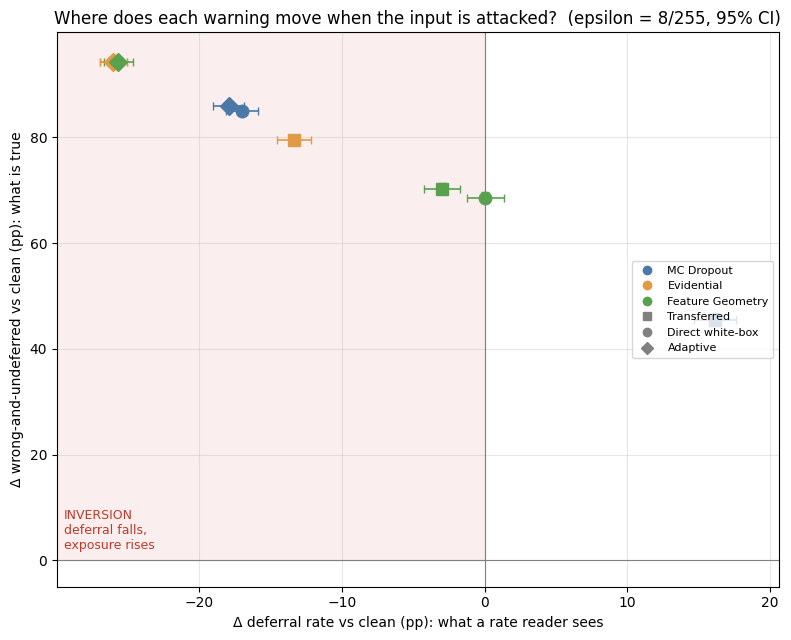

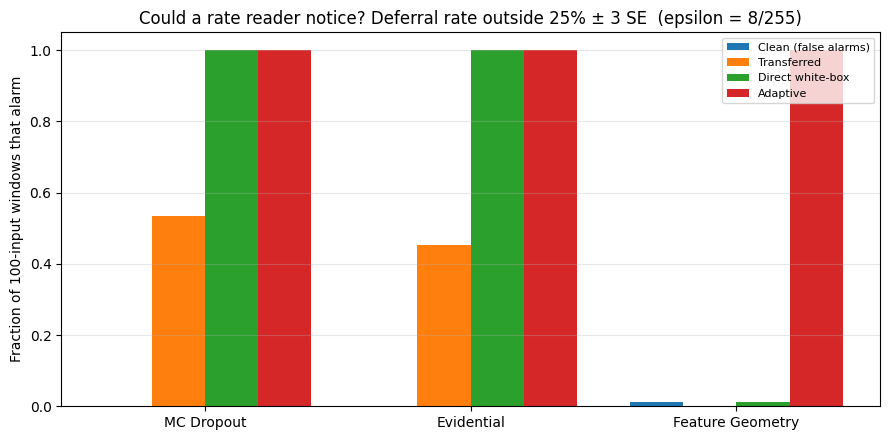

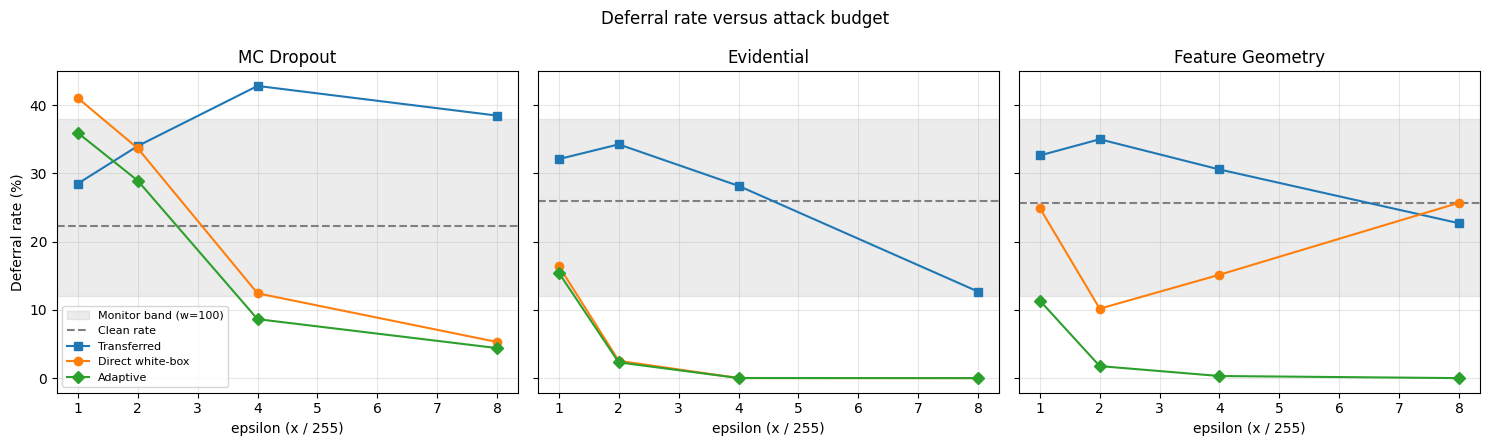

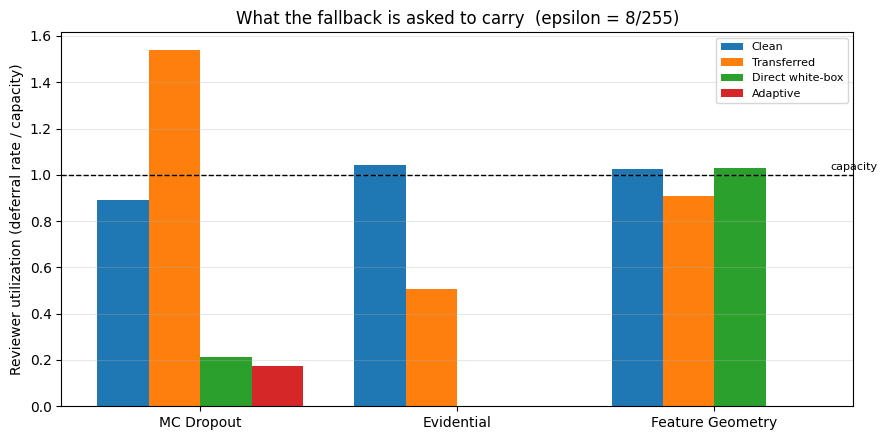

In [14]:
# ─────────────────────────────────────────────────────────────
# Part L: Figures
# ─────────────────────────────────────────────────────────────
COLORS = {"mc_dropout": "#4C78A8", "evidential": "#E39A45", "geometry": "#59A14F"}
MARKERS = {"transferred": "s", "direct_whitebox": "o", "adaptive": "D"}
LABELS = {"transferred": "Transferred", "direct_whitebox": "Direct white-box", "adaptive": "Adaptive"}

# Figure 1: change in what the rate reader sees versus change in what is true
fig, ax = plt.subplots(figsize=(8, 6.5))
d = main_df[main_df["condition"] != "clean"]
x_min = min(-5, float((d["ddef_lo"]).min()) - 3)
x_max = max(5, float((d["ddef_hi"]).max()) + 3)
y_max = max(10, float((d["dexp_hi"]).max()) + 5)
ax.fill([x_min, 0, 0, x_min], [0, 0, y_max, y_max], color="#C0392B", alpha=0.08)
ax.text(x_min + 0.5, 1.5, "INVERSION\ndeferral falls,\nexposure rises", color="#C0392B", fontsize=9, va="bottom")
for r in d.itertuples():
    ax.errorbar(r.ddef, r.dexp,
                xerr=[[r.ddef - r.ddef_lo], [r.ddef_hi - r.ddef]],
                yerr=[[r.dexp - r.dexp_lo], [r.dexp_hi - r.dexp]],
                fmt=MARKERS[r.condition], color=COLORS[r.mechanism], ms=9, capsize=3, lw=1.2)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlim(x_min, x_max); ax.set_ylim(-5, y_max)
ax.set_xlabel("Δ deferral rate vs clean (pp): what a rate reader sees")
ax.set_ylabel("Δ wrong-and-undeferred vs clean (pp): what is true")
ax.set_title("Where does each warning move when the input is attacked?  (epsilon = 8/255, 95% CI)")
handles = [plt.Line2D([], [], marker="o", ls="", color=COLORS[m], label=DISPLAY[m]) for m in MECHANISMS]
handles += [plt.Line2D([], [], marker=MARKERS[c], ls="", color="gray", label=LABELS[c]) for c in CONDITIONS_ATTACK]
ax.legend(handles=handles, loc="center right", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "fig1_person_vs_engineer.png", dpi=200); plt.show()

# Figure 2: monitor detection (w = 100)
fig, ax = plt.subplots(figsize=(9, 4.5))
conds = ["clean"] + CONDITIONS_ATTACK
width = 0.2
for i, c in enumerate(conds):
    vals = [float(main_df[(main_df["mechanism"] == m) & (main_df["condition"] == c)]["monitor_w100"].iloc[0])
            for m in MECHANISMS]
    ax.bar(np.arange(len(MECHANISMS)) + (i - 1.5) * width, vals, width,
           label=("Clean (false alarms)" if c == "clean" else LABELS[c]))
ax.set_xticks(np.arange(len(MECHANISMS))); ax.set_xticklabels([DISPLAY[m] for m in MECHANISMS])
ax.set_ylabel("Fraction of 100-input windows that alarm"); ax.set_ylim(0, 1.05)
ax.set_title("Could a rate reader notice? Deferral rate outside 25% ± 3 SE  (epsilon = 8/255)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "fig2_rate_monitor.png", dpi=200); plt.show()

# Figure 3: deferral rate versus budget, with the monitor band
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
band_lo = float(main_df["band_lo_w100"].dropna().iloc[0]); band_hi = float(main_df["band_hi_w100"].dropna().iloc[0])
for ax, m in zip(axes, MECHANISMS):
    ax.axhspan(band_lo, band_hi, color="gray", alpha=0.15, label="Monitor band (w=100)")
    clean_def = float(sweep_df[(sweep_df["mechanism"] == m) & (sweep_df["condition"] == "clean")]["deferral_rate"].iloc[0])
    ax.axhline(clean_def, ls="--", color="gray", label="Clean rate")
    for c in CONDITIONS_ATTACK:
        s = sweep_df[(sweep_df["mechanism"] == m) & (sweep_df["condition"] == c)].sort_values("epsilon_255")
        ax.plot(s["epsilon_255"], s["deferral_rate"], marker=MARKERS[c], label=LABELS[c])
    ax.set_title(DISPLAY[m]); ax.set_xlabel("epsilon (x / 255)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Deferral rate (%)"); axes[0].legend(fontsize=8)
fig.suptitle("Deferral rate versus attack budget")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "fig3_budget_sweep_deferral.png", dpi=200); plt.show()

# Figure 4: reviewer utilization at 8/255
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, c in enumerate(conds):
    vals = [float(main_df[(main_df["mechanism"] == m) & (main_df["condition"] == c)]["utilization"].iloc[0])
            for m in MECHANISMS]
    ax.bar(np.arange(len(MECHANISMS)) + (i - 1.5) * width, vals, width,
           label=("Clean" if c == "clean" else LABELS[c]))
ax.axhline(1.0, color="black", ls="--", lw=1)
ax.text(2.45, 1.02, "capacity", fontsize=8)
ax.set_xticks(np.arange(len(MECHANISMS))); ax.set_xticklabels([DISPLAY[m] for m in MECHANISMS])
ax.set_ylabel("Reviewer utilization (deferral rate / capacity)")
ax.set_title("What the fallback is asked to carry  (epsilon = 8/255)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "fig4_reviewer_utilization.png", dpi=200); plt.show()


In [15]:
# ─────────────────────────────────────────────────────────────
# Part M: Summary for the essay (plain-text key facts, then save)
# ─────────────────────────────────────────────────────────────
print("=" * 70)
print("KEY FACTS" + ("  [QUICK TEST: NOT FOR PUBLICATION]" if QUICK_TEST else ""))
print("=" * 70)
for r in main_df[main_df["condition"] != "clean"].itertuples():
    detect = "monitor alarms in {:.0f}% of 100-input windows".format(100 * r.monitor_w100)
    auc = "rank info n/a (all wrong)" if math.isnan(r.auroc_error) else f"AUROC {r.auroc_error:.3f}"
    print(f"{DISPLAY[r.mechanism]:<17}{r.condition:<17}{r.verdict:<18}"
          f"Δdef {r.ddef:+6.2f}pp | Δexp {r.dexp:+6.2f}pp | {detect} | "
          f"utilization {r.utilization:.2f} | recalibration gain {r.recalibration_gain_pp:+.2f}pp | {auc}")

summary = {
    "quick_test": QUICK_TEST, "n_eval": N_EVAL, "bootstrap_B": BOOTSTRAP_B,
    "monitor": {"windows": WINDOW_SIZES, "z": MONITOR_Z, "p0": TARGET_DEFERRAL},
    "review_capacity_assumption": REVIEW_CAPACITY,
    "reproduction": REPRODUCTION,
    "sweep_epsilons_255": [MAIN_EPSILON_255] + SWEEP_EPSILONS_255,
}
with open(RESULTS_DIR / "essay11_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print(f"\nSaved results to {RESULTS_DIR}/")


KEY FACTS
MC Dropout       transferred      RESPONSIVE        Δdef +16.16pp | Δexp +45.49pp | monitor alarms in 53% of 100-input windows | utilization 1.54 | recalibration gain -10.77pp | AUROC 0.328
MC Dropout       direct_whitebox  INVERTED          Δdef -17.01pp | Δexp +85.04pp | monitor alarms in 100% of 100-input windows | utilization 0.21 | recalibration gain +19.71pp | rank info n/a (all wrong)
MC Dropout       adaptive         INVERTED          Δdef -17.91pp | Δexp +85.93pp | monitor alarms in 100% of 100-input windows | utilization 0.18 | recalibration gain +20.60pp | rank info n/a (all wrong)
Evidential       transferred      INVERTED          Δdef -13.33pp | Δexp +79.45pp | monitor alarms in 45% of 100-input windows | utilization 0.51 | recalibration gain +11.83pp | AUROC 0.333
Evidential       direct_whitebox  INVERTED          Δdef -26.01pp | Δexp +94.36pp | monitor alarms in 100% of 100-input windows | utilization 0.00 | recalibration gain +25.00pp | rank info n/a (all wr